In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from scipy.stats import poisson


In [5]:
# Lab 0 — Starter Dataset

data = {
    "demand": [42, 45, 48, 51, 54, 56, 59, 62, 65, 90],
    "supply": [55, 54, 53, 52, 50, 49, 48, 46, 44, 65],
    "wait_min": [4, 5, 5, 6, 7, 7, 8, 9, 11, 6],
    "distance_km": [3.2, 4.8, 6.1, 5.5, 7.0,
                    8.4, 9.2, 10.5, 12.0, 11.0],
    "fare_cad": [10, 13, 16, 15, 19, 22, 24, 27, 31, 29],
    "peak": ["No", "No", "No", "Yes", "Yes",
             "Yes", "Yes", "Yes", "Yes", "Yes"],
    "late": [0, 0, 0, 0, 1, 0, 1, 1, 1, 0]
}

df = pd.DataFrame(data)

display(df)
print("Shape:", df.shape)

,demand,supply,wait_min,distance_km,fare_cad,peak,late
0,42,55,4,3.2,10,No,0
1,45,54,5,4.8,13,No,0
2,48,53,5,6.1,16,No,0
3,51,52,6,5.5,15,Yes,0
4,54,50,7,7.0,19,Yes,1
5,56,49,7,8.4,22,Yes,0
6,59,48,8,9.2,24,Yes,1
7,62,46,9,10.5,27,Yes,1
8,65,44,11,12.0,31,Yes,1
9,90,65,6,11.0,29,Yes,0


Shape: (10, 7)


Text(0.5, 0, 'demand')

Text(0, 0.5, 'Waiting Time (minutes)')

Text(0.5, 1.0, 'Wait vs. demand')

Text(0.5, 0, 'supply')

Text(0, 0.5, 'Waiting Time (minutes)')

Text(0.5, 1.0, 'Wait vs. supply')

... (2 outputs left out)

Text(0.5, 1.0, 'Wait vs. distance_km')

Text(0.5, 0, 'fare_cad')

Text(0, 0.5, 'Waiting Time (minutes)')

Text(0.5, 1.0, 'Wait vs. fare_cad')

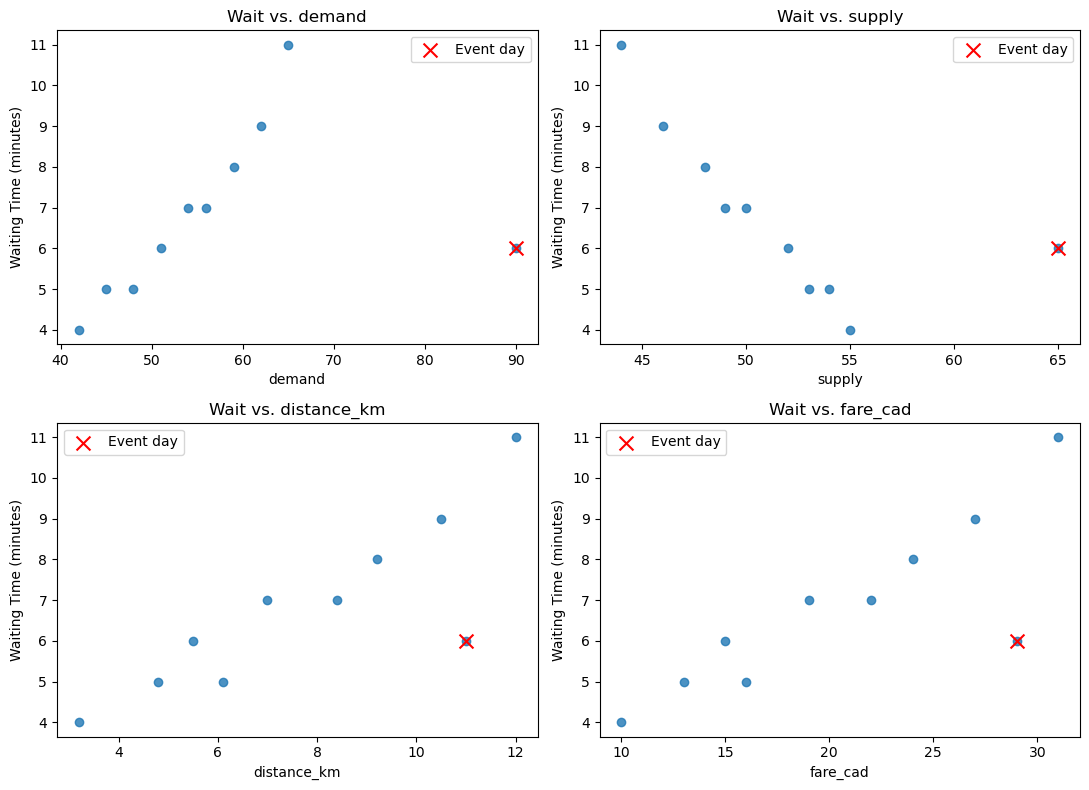

In [6]:
# Q1 — Scatterplots: Relationships with Waiting Time

variables = [
    "demand",
    "supply",
    "distance_km",
    "fare_cad"
]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, variable in zip(axes.flat, variables):

    ax.scatter(
        df[variable],
        df["wait_min"],
        alpha=0.8
    )

    # Highlight event-day observation
    ax.scatter(
        df.loc[9, variable],
        df.loc[9, "wait_min"],
        color="red",
        s=100,
        marker="x",
        label="Event day"
    )

    ax.set_xlabel(variable)
    ax.set_ylabel("Waiting Time (minutes)")
    ax.set_title(f"Wait vs. {variable}")
    ax.legend()

plt.tight_layout()
plt.show()

In [7]:
# Q2 — Covariance and Correlation Matrices

numeric_df = df.select_dtypes(include="number")

# Sample covariance matrix
cov_matrix = numeric_df.cov()

# Pearson correlation matrix
corr_matrix = numeric_df.corr()

print("Covariance matrix:")
display(cov_matrix.round(3))

print("Correlation matrix:")
display(corr_matrix.round(3))

Covariance matrix:


,demand,supply,wait_min,distance_km,fare_cad,late
demand,186.400,28.756,11.600,32.384,80.867,1.244
supply,28.756,34.489,-8.533,-3.958,-8.733,-2.044
wait_min,11.600,-8.533,4.400,5.093,12.356,0.867
distance_km,32.384,-3.958,5.093,8.496,20.776,0.847
fare_cad,80.867,-8.733,12.356,20.776,50.933,2.067
late,1.244,-2.044,0.867,0.847,2.067,0.267


Correlation matrix:


,demand,supply,wait_min,distance_km,fare_cad,late
demand,1.000,0.359,0.405,0.814,0.830,0.177
supply,0.359,1.000,-0.693,-0.231,-0.208,-0.674
wait_min,0.405,-0.693,1.000,0.833,0.825,0.800
distance_km,0.814,-0.231,0.833,1.000,0.999,0.563
fare_cad,0.830,-0.208,0.825,0.999,1.000,0.561
late,0.177,-0.674,0.800,0.563,0.561,1.000


In [8]:
# Important numerical results

print("Cov(Demand, Wait):",
      df["demand"].cov(df["wait_min"]))

print("Corr(Demand, Wait):",
      df["demand"].corr(df["wait_min"]))

print("Corr(Supply, Wait):",
      df["supply"].corr(df["wait_min"]))

print("Corr(Distance, Fare):",
      df["distance_km"].corr(df["fare_cad"]))

Cov(Demand, Wait): 11.599999999999998
Corr(Demand, Wait): 0.4050500563951569
Corr(Supply, Wait): -0.6927120952173104
Corr(Distance, Fare): 0.9987409663532942


Sample interpretation:
Distance and fare have the strongest positive linear relationship (r ≈ 0.999). Supply is negatively correlated with waiting time (r ≈ −0.693), while demand has a moderately positive correlation with waiting time (r ≈ 0.405). The event-day observation influences several correlations, so the results should be interpreted cautiously.

In [9]:
# Q3 — Pearson vs. Spearman Correlation

pearson_r = df["demand"].corr(
    df["wait_min"],
    method="pearson"
)

spearman_r = df["demand"].corr(
    df["wait_min"],
    method="spearman"
)

print(f"Pearson correlation:  {pearson_r:.4f}")
print(f"Spearman correlation: {spearman_r:.4f}")

Pearson correlation:  0.4051
Spearman correlation: 0.7768


Spearman correlation (0.777) is stronger than Pearson correlation (0.405). The relationship is generally increasing, but the event-day observation weakens the linear association. Pearson is more sensitive to extreme numerical values, while Spearman uses ranks to summarize monotonic association.

In [10]:
# Q4 — Event-Day Observation and Sensitivity Analysis

# Step 1 — Flag the event day

df["event_day"] = False

df.loc[9, "event_day"] = True

display(df[df["event_day"]])

,demand,supply,wait_min,distance_km,fare_cad,peak,late,event_day
9,90,65,6,11.0,29,Yes,0,True


In [11]:
# Step 2 — Compare correlations

# Original correlation
r_all = df["demand"].corr(df["wait_min"])

# Exclude flagged observation for sensitivity analysis
df_regular = df.loc[~df["event_day"]].copy()

r_regular = df_regular["demand"].corr(
    df_regular["wait_min"]
)

print(f"All observations: {r_all:.4f}")
print(f"Without event day: {r_regular:.4f}")
print(f"Difference: {r_regular - r_all:.4f}")

All observations: 0.4051
Without event day: 0.9753
Difference: 0.5702


Removing the event-day observation increases the correlation from approximately 0.41 to 0.98. This shows that a single influential observation can substantially change the estimated relationship. However, the event-day observation should not automatically be deleted. It may represent a legitimate operating regime with both high demand and high supply.

In [ ]:
# Q5 — Marginal and Conditional Probabilities

# Step 1 — Contingency table

frequency_table = pd.crosstab(
    df["peak"],
    df["late"],
    margins=True
)

display(frequency_table)

In [ ]:
# Step 2 — Calculate probabilities

# Marginal probability
p_late = (df["late"] == 1).mean()

# Conditional probability: Late given Peak
p_late_given_peak = df.loc[
    df["peak"] == "Yes", "late"
].mean()

# Conditional probability: Peak given Late
p_peak_given_late = (
    df.loc[df["late"] == 1, "peak"] == "Yes"
).mean()

print("P(Late):", p_late)
print("P(Late | Peak):", p_late_given_peak)
print("P(Peak | Late):", p_peak_given_late)

In [12]:
# Q6 — Bernoulli Simulation


SyntaxError: invalid character '—' (U+2014) (1882924905.py, line 3)

Step 1 — Estimate Bernoulli parameter

$\hat p=\frac4{10}=0.4$

$X\sim\operatorname{Bernoulli}(0.4)$


$P(X=1)=0.4,\qquad P(X=0)=0.6$

In [13]:
# Step 2 — Simulate

p = df["late"].mean()

rng = np.random.default_rng(42)

simulation = rng.binomial(
    n=1,
    p=p,
    size=10000
)

empirical_p = simulation.mean()

print("Theoretical P(Late):", p)
print("Empirical P(Late):", empirical_p)
print("Number of simulated late trips:", simulation.sum())

Theoretical P(Late): 0.4
Empirical P(Late): 0.3952
Number of simulated late trips: 3952


In [ ]:
# Step 3 — Compare visually

comparison = pd.DataFrame({
    "Theoretical": [1-p, p],
    "Simulated": [
        (simulation == 0).mean(),
        (simulation == 1).mean()
    ]
}, index=["Not Late", "Late"])

display(comparison)

comparison.plot(kind="bar", figsize=(7, 4))

plt.title("Bernoulli: Theoretical vs. Simulated")
plt.xlabel("Trip Status")
plt.ylabel("Probability")
plt.xticks(rotation=0)
plt.show()

The simulated late-trip probability is approximately 0.395, close to the theoretical value of 0.400. With a large number of independent Bernoulli trials, the simulated relative frequency tends to approach the model probability. However, the model parameter was estimated from only ten real observations, so the simulation does not eliminate uncertainty about the true lateness rate.

In [14]:
# Q7 — Poisson Distribution for Ride Requests

# Step 1 — Estimate the mean demand

mean_demand = df["demand"].mean()

print("Mean demand:", mean_demand)

Mean demand: 57.2
